# 01 · Análisis exploratorio (EDA) — FireWatch Boyacá

**Dueño:** B · **Tarea:** B8 · **Entrada:** `data/gold/` (después del data freeze) · **Requisito:** R6 (≥6 visualizaciones con Matplotlib/Seaborn; meta: 7)

Regla: cada gráfico va seguido de una celda **Hallazgo** de 2–3 frases. Esas frases se usan en el IEEE y en la sustentación.

## 0. Carga y verificación
Conteos y reconciliación con silver.

In [1]:
# === Celda 0 · Configuración, carga y verificación ===
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Rutas y parámetros: todo sale de settings.yaml ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load((ROOT / "config/settings.yaml").read_text(encoding="utf-8"))
SILVER = ROOT / CFG["rutas"]["silver"]
GOLD = ROOT / CFG["rutas"]["gold"]
DPTO = CFG["territorio"]["cod_dpto_foco"]
INI = pd.Timestamp(CFG["ventana"]["fecha_inicio"])
FIN = pd.Timestamp(CFG["ventana"]["fecha_fin"])
FIG_DIR = ROOT / "docs/figures/eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Estilo único para todas las figuras ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png")
    print(f"→ docs/figures/eda/{nombre}.png")

# --- Detecciones de Boyacá (vegetación = sin fuentes estáticas) ---
COLS = ["id_det", "fecha", "anio", "mes", "daynight", "confianza", "frp",
        "satelite", "proceso", "fuente_estatica", "cod_mpio", "lat", "lon"]
det = pd.read_parquet(SILVER / "detecciones", columns=COLS,
                      filters=[("cod_dpto", "==", DPTO)])
det["anio"] = det["anio"].astype(int)
det["fecha"] = pd.to_datetime(det["fecha"])
n_estaticas = int(det["fuente_estatica"].sum())
det = det[~det["fuente_estatica"] & det["fecha"].between(INI, FIN)].drop(columns="fuente_estatica")
det["fecha_mes"] = det["fecha"].dt.to_period("M").dt.to_timestamp()

# --- Contexto nacional (gráfica 8): solo conteos por departamento ---
nac = pd.read_parquet(SILVER / "detecciones", columns=["cod_dpto", "fuente_estatica", "fecha"])
nac = nac[~nac["fuente_estatica"] & nac["cod_dpto"].notna()]
dim_dpto = pd.read_parquet(SILVER / "dim_departamento")
det_dpto = (nac.groupby("cod_dpto").size().rename("n_det").reset_index()
               .merge(dim_dpto, on="cod_dpto", how="left")
               .sort_values("n_det", ascending=False))
del nac

# --- Dimensiones y geometría de Boyacá ---
dim_mpio = pd.read_parquet(SILVER / "dim_municipio")
geo = gpd.read_parquet(SILVER / "geo_municipios")
geo = geo[geo["cod_dpto"] == DPTO].merge(dim_mpio, on="cod_mpio")

# --- Grilla municipio × mes CON CEROS ---
meses = pd.date_range(INI, FIN, freq="MS")
grilla = pd.MultiIndex.from_product([dim_mpio["cod_mpio"], meses],
                                    names=["cod_mpio", "fecha_mes"]).to_frame(index=False)
conteo = (det.groupby(["cod_mpio", "fecha_mes"])
             .agg(n_det=("id_det", "size"), frp_total=("frp", "sum")).reset_index())
mm = grilla.merge(conteo, on=["cod_mpio", "fecha_mes"], how="left")
mm = mm.fillna({"n_det": 0, "frp_total": 0.0}).astype({"n_det": int})

# --- Clima: horario → diario (mismas definiciones que build_daily) → mensual ---
clima = pd.read_parquet(SILVER / "clima_horario",
                        columns=["cod_mpio", "fecha", "temp", "rh", "precip", "wind"])
diario = (clima.groupby(["cod_mpio", "fecha"])
               .agg(tmax=("temp", "max"), rh_min=("rh", "min"),
                    precip=("precip", "sum"), wind_max=("wind", "max")).reset_index())
del clima
diario["fecha_mes"] = pd.to_datetime(diario["fecha"]).dt.to_period("M").dt.to_timestamp()
clima_mes = (diario.groupby(["cod_mpio", "fecha_mes"])
                   .agg(precip_mes=("precip", "sum"), tmax_media=("tmax", "mean"),
                        rh_min_media=("rh_min", "mean"), wind_max_media=("wind_max", "mean"))
                   .reset_index())
mm = (mm.merge(clima_mes, on=["cod_mpio", "fecha_mes"], how="left")
        .merge(dim_mpio[["cod_mpio", "nombre", "provincia", "area_km2"]], on="cod_mpio"))
mm["det_100km2"] = mm["n_det"] / mm["area_km2"] * 100

# --- Verificación ---
print(f"Detecciones Boyacá (vegetación): {len(det):,}  | fuentes estáticas excluidas: {n_estaticas:,}")
print(f"Municipios con detecciones: {det['cod_mpio'].nunique()}/{len(dim_mpio)}")
print(f"Grilla: {len(mm):,} filas (esperado {len(dim_mpio) * len(meses):,})")
print(f"Municipio-mes sin detecciones: {(mm['n_det'] == 0).mean():.1%}")
print(f"Clima faltante en la grilla: {mm['precip_mes'].isna().sum()}")
print(f"Provincias cargadas: {dim_mpio['provincia'].notna().sum()}/{len(dim_mpio)}")

assert det["id_det"].is_unique
assert det["cod_mpio"].isin(dim_mpio["cod_mpio"]).all()
assert len(mm) == len(dim_mpio) * len(meses)
assert mm["n_det"].sum() == len(det)

fact = GOLD / "fact_municipio_mes"
if fact.exists():
    g = pd.read_parquet(fact, columns=["cod_mpio", "fecha_mes", "n_det"])
    g["fecha_mes"] = pd.to_datetime(g["fecha_mes"])
    cmp = mm.merge(g, on=["cod_mpio", "fecha_mes"], suffixes=("_silver", "_gold"))
    print(f"Reconciliación con gold: {(cmp['n_det_silver'] != cmp['n_det_gold']).sum()} "
          f"municipio-mes distintos de {len(cmp)}")
else:
    print("Gold aún no existe → reconciliación pendiente (volver a correr tras el freeze).")

Detecciones Boyacá (vegetación): 4,294  | fuentes estáticas excluidas: 712
Municipios con detecciones: 107/123
Grilla: 7,134 filas (esperado 7,134)
Municipio-mes sin detecciones: 87.7%
Clima faltante en la grilla: 0
Provincias cargadas: 0/123
Gold aún no existe → reconciliación pendiente (volver a correr tras el freeze).


## 1. Serie mensual de detecciones 2022-01 → 2026-10 (línea; anotar La Niña 2022 / El Niño 2023–24)

→ docs/figures/eda/eda01_monthly_series_enso.png


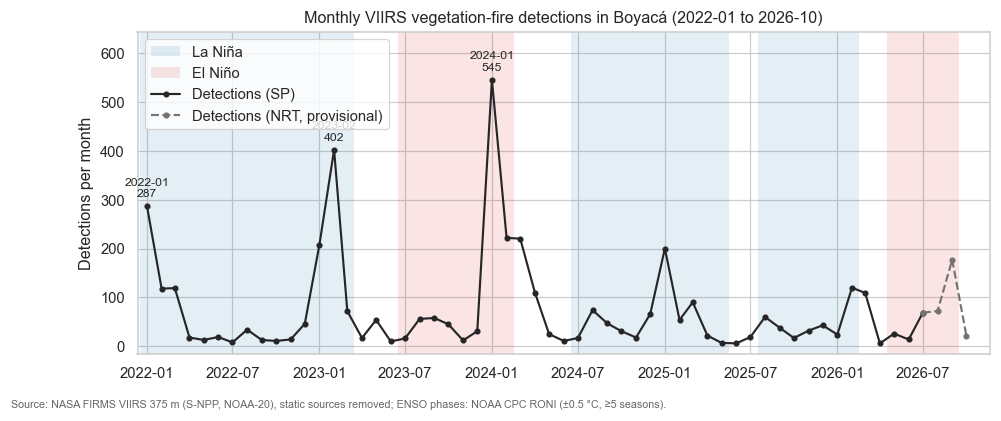

Detecciones por año:
 anio
2022     700
2023     981
2024    1386
2025     588
2026     639 

Top 5 meses:
  fecha_mes  n_det
2024-01-01    545
2023-02-01    402
2022-01-01    287
2024-02-01    222
2024-03-01    220 

                    count   mean  median
fase                                    
La Niña                33   71.0    38.0
Neutral / sin dato     12   50.8    20.5
El Niño                13  103.3    56.0


In [7]:
# === Gráfica 1 · Serie mensual de detecciones con fases ENSO (RONI, NOAA CPC) ===
roni = pd.read_csv(ROOT / "config/enso_roni.csv", comment="#")
roni["fecha_mes"] = pd.to_datetime(dict(year=roni["anio"], month=roni["mes_central"], day=1))

def fases_enso(valores, umbral=0.5, minimo=5):
    """+1 El Niño, -1 La Niña, 0 neutral: umbral ±0.5 °C sostenido ≥ 5 temporadas."""
    s = pd.Series(np.where(valores >= umbral, 1, np.where(valores <= -umbral, -1, 0)))
    racha = (s != s.shift()).cumsum()
    largo = s.groupby(racha).transform("size")
    return np.where(largo >= minimo, s, 0)

roni["fase"] = fases_enso(roni["roni"].to_numpy())
serie = mm.groupby("fecha_mes", as_index=False)["n_det"].sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
r = roni[roni["fecha_mes"].between(INI, FIN)].reset_index(drop=True)
ya = set()
for _, b in r.groupby((r["fase"] != r["fase"].shift()).cumsum()):
    f = b["fase"].iloc[0]
    if f == 0:
        continue
    color, etiqueta = ("tab:blue", "La Niña") if f < 0 else ("tab:red", "El Niño")
    ax.axvspan(b["fecha_mes"].iloc[0] - pd.Timedelta(days=15),
               b["fecha_mes"].iloc[-1] + pd.Timedelta(days=15),
               color=color, alpha=0.12, lw=0, label=None if etiqueta in ya else etiqueta)
    ya.add(etiqueta)

nrt_ini = det.loc[det["proceso"] == "NRT", "fecha_mes"].min()
sp = serie[serie["fecha_mes"] < nrt_ini]
nrt = serie[serie["fecha_mes"] >= nrt_ini - pd.DateOffset(months=1)]   # une con el último mes SP
ax.plot(sp["fecha_mes"], sp["n_det"], marker="o", ms=3, lw=1.4, color="0.15", label="Detections (SP)")
ax.plot(nrt["fecha_mes"], nrt["n_det"], marker="o", ms=3, lw=1.4, ls="--", color="0.45",
        label="Detections (NRT, provisional)")
for _, t in serie.nlargest(3, "n_det").iterrows():
    ax.annotate(f"{t.fecha_mes:%Y-%m}\n{int(t.n_det)}", (t.fecha_mes, t.n_det),
                textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set(title="Monthly VIIRS vegetation-fire detections in Boyacá (2022-01 to 2026-10)",
       ylabel="Detections per month", xlabel="")
ax.set_xlim(INI - pd.Timedelta(days=20), FIN + pd.Timedelta(days=20))
ax.set_ylim(bottom=-15, top=serie["n_det"].max() * 1.18)
ax.legend(loc="upper left", frameon=True)
fig.text(0.01, -0.02, "Source: NASA FIRMS VIIRS 375 m (S-NPP, NOAA-20), static sources removed; "
         "ENSO phases: NOAA CPC RONI (±0.5 °C, ≥5 seasons).", fontsize=7, color="0.4")
guardar(fig, "eda01_monthly_series_enso")
plt.show()

# --- Números para el Hallazgo ---
print("Detecciones por año:\n", det.groupby("anio").size().to_string(), "\n")
print("Top 5 meses:\n", serie.nlargest(5, "n_det").to_string(index=False), "\n")
pf = serie.merge(roni[["fecha_mes", "fase"]], on="fecha_mes", how="left").fillna({"fase": 0})
print(pf.groupby("fase")["n_det"].agg(["count", "mean", "median"])
        .rename(index={-1: "La Niña", 0: "Neutral / sin dato", 1: "El Niño"}).round(1))

**Hallazgo 1.** Las detecciones siguen un ciclo estacional fuerte: el pico ocurre cada año en enero–febrero (temporada seca), con un pico secundario más débil en julio–septiembre. El máximo de la serie (545 detecciones, enero de 2024) coincide con El Niño 2023–24; enero–marzo de 2024 concentra el 71 % de las detecciones de ese año. Sin embargo, La Niña no suprime la temporada (402 en febrero de 2023): ENSO modula la intensidad del pico estacional, no lo origina. *Pendiente:* verificar el efecto SP→NRT antes de interpretar el aumento de septiembre de 2026.

## 2. Estacionalidad: heatmap mes × año

→ docs/figures/eda/eda02_seasonality_heatmap.png


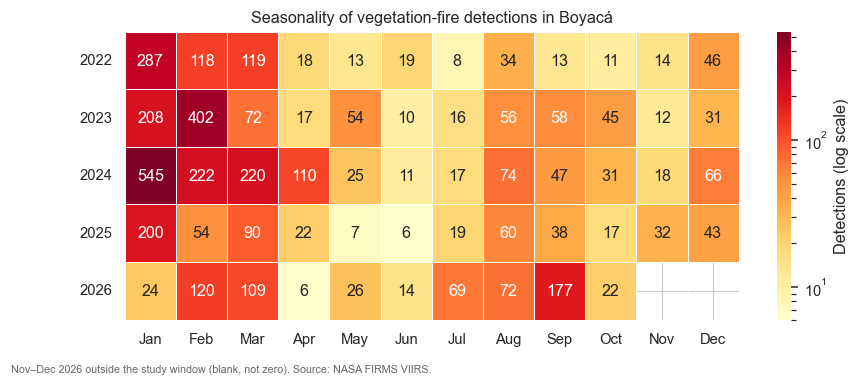

Porcentaje del año en ene–mar:
 anio
2022    74.9
2023    69.5
2024    71.2
2025    58.5
2026    39.6 

Porcentaje de cada mes sobre el total 2022–2026:
 mes
Jan    29.4
Feb    21.3
Mar    14.2
Apr     4.0
May     2.9
Jun     1.4
Jul     3.0
Aug     6.9
Sep     7.8
Oct     2.9
Nov     1.8
Dec     4.3


In [5]:
# === Gráfica 2 · Estacionalidad: heatmap mes × año ===
from matplotlib.colors import LogNorm

tabla = (mm.assign(anio=mm["fecha_mes"].dt.year, mes=mm["fecha_mes"].dt.month)
           .pivot_table(index="anio", columns="mes", values="n_det", aggfunc="sum"))
MESES_EN = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 3.4))
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5, linecolor="white",
            norm=LogNorm(vmin=max(1, tabla.min().min()), vmax=tabla.max().max()),
            mask=tabla.isna(), cbar_kws={"label": "Detections (log scale)"}, ax=ax)
ax.set_xticklabels(MESES_EN, rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set(title="Seasonality of vegetation-fire detections in Boyacá", xlabel="", ylabel="")
fig.text(0.01, -0.03, "Nov–Dec 2026 outside the study window (blank, not zero). "
         "Source: NASA FIRMS VIIRS.", fontsize=7, color="0.4")
guardar(fig, "eda02_seasonality_heatmap")
plt.show()

# --- Números para el Hallazgo ---
anual = tabla.sum(axis=1)
temporada = tabla[[1, 2, 3]].sum(axis=1)
print("Porcentaje del año en ene–mar:\n", (temporada / anual * 100).round(1).to_string(), "\n")
print("Porcentaje de cada mes sobre el total 2022–2026:\n",
      (tabla.sum() / tabla.sum().sum() * 100).round(1).rename(dict(enumerate(MESES_EN, 1))).to_string())

In [6]:
# === Diagnóstico: ¿enero de 2026 es real o un hueco de datos? ===
d = pd.read_parquet(SILVER / "detecciones", columns=["fecha", "satelite", "proceso", "fuente_estatica"])
d = d[~d["fuente_estatica"]].copy()
d["fecha"] = pd.to_datetime(d["fecha"])
d["periodo"] = d["fecha"].dt.to_period("M")

# Hipótesis A: ¿cae también Colombia? ¿falta un satélite?
ene = d[d["periodo"].dt.month == 1]
print("Colombia, enero de cada año, por satélite:\n",
      ene.groupby([ene["periodo"].dt.year, "satelite"]).size().unstack().to_string(), "\n")
print("Días con datos en enero de 2026, por satélite (máx. 31):\n",
      d[d["periodo"] == pd.Period("2026-01", "M")].groupby("satelite")["fecha"].nunique().to_string(), "\n")

# Hipótesis B: ¿dónde pasa de SP a NRT?
ult = d[d["periodo"] >= pd.Period("2025-10", "M")]
print("Colombia, oct-2025 → oct-2026, por satélite y proceso:\n",
      ult.groupby(["periodo", "satelite", "proceso"]).size().unstack(["satelite", "proceso"])
         .fillna(0).astype(int).to_string(), "\n")

# Hipótesis C: ¿enero de 2026 fue lluvioso en Boyacá?
pe = mm[mm["fecha_mes"].dt.month == 1]
print("Boyacá, precipitación media de enero por municipio (mm):\n",
      pe.groupby(pe["fecha_mes"].dt.year)["precip_mes"].mean().round(1).to_string())
del d, ene, ult

Colombia, enero de cada año, por satélite:
 satelite      N    N20
periodo               
2022      38405  38003
2023      11653  11388
2024      22546  22761
2025      12953  13833
2026       6182   5466 

Días con datos en enero de 2026, por satélite (máx. 31):
 satelite
N      31
N20    31 

Colombia, oct-2025 → oct-2026, por satélite y proceso:
 satelite      N    N20     N   N20
proceso      SP     SP   NRT   NRT
periodo                           
2025-10    2067   2056     0     0
2025-11    2346   2494     0     0
2025-12    7808   7722     0     0
2026-01    6182   5466     0     0
2026-02   15681  14993     0     0
2026-03   20242  19771     0     0
2026-04    3439   3715     0     0
2026-05    2096   1898     0     0
2026-06    1705   2181     0     0
2026-07    2803   3530     0     0
2026-08       0      0  5475  5329
2026-09       0      0  4535  4398
2026-10       0      0  2506  2597 

Boyacá, precipitación media de enero por municipio (mm):
 fecha_mes
2022     59.4
2023

**Hallazgo 2.** El régimen es bimodal: enero–marzo concentra el 64,9 % de las detecciones y agosto–septiembre el 14,7 %; los mínimos (abril–mayo, octubre–noviembre) coinciden con las temporadas de lluvia andinas. En el mismo mes, El Niño duplica la actividad (enero 2024: 545, frente a 200–287 en otros años). Enero de 2026 (24 detecciones) no es un error de datos —cobertura completa de ambos satélites, procesamiento SP— sino un enero excepcionalmente lluvioso (207 mm frente a 21 mm en 2024; 2022: 59 mm). La precipitación explica mejor la intensidad de la temporada que la fase ENSO por sí sola.Enero de 2022, con La Niña pero seco (59 mm), registró 287 detecciones: la precipitación observada ordena los eneros (ρ de Spearman = −0,9, n = 5) mejor que la fase ENSO.

## 3. Distribución del FRP (histograma con escala logarítmica)

→ docs/figures/eda/eda03_frp_distribution.png


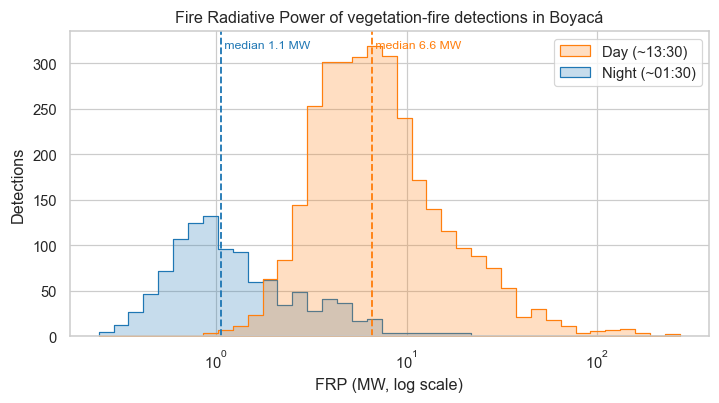

count    4294.00
mean        8.64
std        14.61
min         0.24
50%         4.99
90%        18.17
99%        64.22
max       274.09 

El 10 % de detecciones más intensas concentra el 44.3% del FRP total
Media / mediana = 1.7  (≈1 si fuera simétrica)

          count  median   mean
daynight                      
D          3215    6.59  10.94
N          1079    1.06   1.78


In [9]:
# === Gráfica 3 · Distribución del FRP (escala log, día vs noche) ===
frp = det["frp"]
bins = np.logspace(np.log10(frp.min()), np.log10(frp.max()), 40)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
sns.histplot(data=det, x="frp", hue="daynight", hue_order=["D", "N"], bins=bins,
             element="step", palette={"D": "tab:orange", "N": "tab:blue"}, ax=ax)
ax.set_xscale("log")
for dn, color in [("D", "tab:orange"), ("N", "tab:blue")]:
    v = det.loc[det["daynight"] == dn, "frp"].median()
    ax.axvline(v, color=color, ls="--", lw=1.2)
    ax.text(v, ax.get_ylim()[1] * 0.97, f" median {v:.1f} MW", color=color, fontsize=8, va="top")
leg = ax.get_legend()
leg.set_title("")
for t, nombre in zip(leg.texts, ["Day (~13:30)", "Night (~01:30)"]):
    t.set_text(nombre)
ax.set(title="Fire Radiative Power of vegetation-fire detections in Boyacá",
       xlabel="FRP (MW, log scale)", ylabel="Detections")
guardar(fig, "eda03_frp_distribution")
plt.show()

# --- Números para el Hallazgo ---
print(frp.describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string(), "\n")
s = frp.sort_values(ascending=False)
top10 = s.iloc[: int(len(s) * 0.10)].sum() / s.sum()
print(f"El 10 % de detecciones más intensas concentra el {top10:.1%} del FRP total")
print(f"Media / mediana = {frp.mean() / frp.median():.1f}  (≈1 si fuera simétrica)\n")
print(det.groupby("daynight")["frp"].agg(["count", "median", "mean"]).round(2))

**Hallazgo 3.** El FRP tiene cola pesada: la mediana es 5,0 MW, pero el 10 % más intenso concentra el 44,3 % de la energía radiada (máximo 274 MW). La distribución es bimodal porque mezcla dos poblaciones: las detecciones diurnas (75 %, mediana 6,6 MW) captan el pico de actividad de la tarde, y las nocturnas (mediana 1,1 MW) fuegos residuales que el sensor detecta mejor con fondo frío. Consecuencia: los agregados de FRP deben usar la mediana o separar día y noche, porque un promedio mezclado depende de la proporción día/noche y no solo de la intensidad.

## 4. FRP por provincia (boxplot)

→ docs/figures/eda/eda04_density_map.png


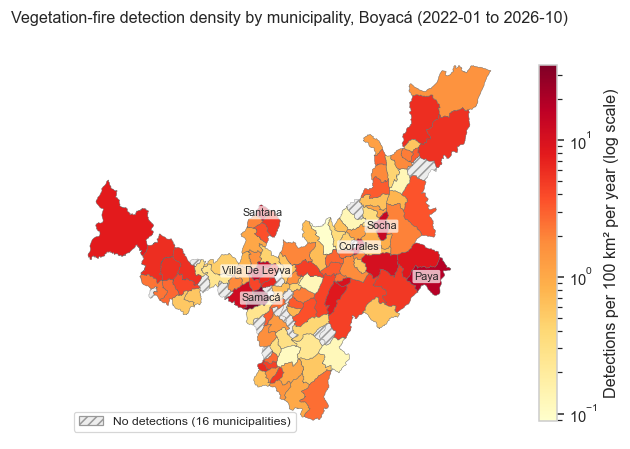

Top 10 por DENSIDAD:
         nombre  n_det  area_km2  dens_anual
        SAMACÁ    286    167.32       35.37
          PAYA    382    442.76       17.85
      CORRALES     46     60.73       15.67
VILLA DE LEYVA     86    126.38       14.08
         SOCHA     99    149.88       13.67
       SANTANA     41     67.85       12.50
       RÁQUIRA    127    220.33       11.93
        MONGUA    183    360.04       10.52
       CUÍTIVA     21     44.04        9.87
         PISBA    197    463.88        8.79 

Top 10 por CONTEO:
              nombre  n_det  area_km2  dens_anual
      PUERTO BOYACÁ    573   1512.08        7.84
               PAYA    382    442.76       17.85
             SAMACÁ    286    167.32       35.37
GÜICÁN DE LA SIERRA    261    949.90        5.68
          AQUITANIA    209    940.35        4.60
              PISBA    197    463.88        8.79
            CHISCAS    188    657.28        5.92
             MONGUA    183    360.04       10.52
     LABRANZAGRANDE    144    5

In [10]:
# === Gráfica 4 · Mapa de densidad de detecciones por municipio ===
from matplotlib.patches import Patch

anios = len(meses) / 12
dens = mm.groupby("cod_mpio", as_index=False)["n_det"].sum()
g4 = geo.merge(dens, on="cod_mpio").to_crs("EPSG:9377")          # MAGNA-SIRGAS Origen Nacional
g4["dens_anual"] = g4["n_det"] / g4["area_km2"] * 100 / anios    # det / 100 km² / año

cero, pos = g4[g4["n_det"] == 0], g4[g4["n_det"] > 0]
fig, ax = plt.subplots(figsize=(6.5, 7))
cero.plot(ax=ax, color="0.93", edgecolor="0.6", linewidth=0.3, hatch="////")
pos.plot(ax=ax, column="dens_anual", cmap="YlOrRd", edgecolor="0.4", linewidth=0.3,
         norm=LogNorm(vmin=pos["dens_anual"].min(), vmax=pos["dens_anual"].max()), legend=True,
         legend_kwds={"label": "Detections per 100 km² per year (log scale)", "shrink": 0.6})
for _, r in g4.nlargest(6, "dens_anual").iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r["nombre"].title(), (p.x, p.y), fontsize=7, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
ax.legend(handles=[Patch(facecolor="0.93", edgecolor="0.6", hatch="////",
                         label=f"No detections ({len(cero)} municipalities)")],
          loc="lower left", fontsize=8, frameon=True)
ax.set_axis_off()
ax.set_title("Vegetation-fire detection density by municipality, Boyacá (2022-01 to 2026-10)")
guardar(fig, "eda04_density_map")
plt.show()

# --- Números para el Hallazgo ---
cols = ["nombre", "n_det", "area_km2", "dens_anual"]
print("Top 10 por DENSIDAD:\n", g4.nlargest(10, "dens_anual")[cols].round(2).to_string(index=False), "\n")
print("Top 10 por CONTEO:\n", g4.nlargest(10, "n_det")[cols].round(2).to_string(index=False), "\n")
orden = g4.sort_values("n_det", ascending=False)["n_det"]
print(f"Los 10 municipios con más detecciones concentran el {orden.head(10).sum() / orden.sum():.1%}")
print(f"Densidad departamental: {g4['n_det'].sum() / g4['area_km2'].sum() * 100 / anios:.2f} det/100 km²/año")

In [11]:
# === Diagnóstico 2: ¿hay fuentes industriales que la máscara no atrapó? ===
TAM = CFG["firms"]["mascara_estatica"]["tamano_celda_grados"]          # 0.005° ≈ 550 m
d2 = det.merge(dim_mpio[["cod_mpio", "nombre"]], on="cod_mpio")
d2["celda"] = (np.floor(d2["lat"] / TAM).astype(int).astype(str) + "_" +
               np.floor(d2["lon"] / TAM).astype(int).astype(str))
d2["periodo"] = d2["fecha"].dt.to_period("M")

por_celda = d2.groupby("celda").agg(n=("id_det", "size"), meses=("periodo", "nunique"),
                                    anios=("anio", "nunique"), lat=("lat", "mean"),
                                    lon=("lon", "mean"), nombre=("nombre", "first"))
persistentes = por_celda[(por_celda["meses"] >= 6) & (por_celda["anios"] >= 3)]
d2["persistente"] = d2["celda"].isin(persistentes.index)

res = d2.groupby("nombre").agg(
    n=("id_det", "size"), celdas=("celda", "nunique"),
    pct_persist=("persistente", "mean"),
    pct_noche=("daynight", lambda s: (s == "N").mean()),
    pct_meses_lluvia=("mes", lambda s: s.isin([4, 5, 10, 11]).mean()),
    frp_mediana=("frp", "median"))
res["det_por_celda"] = res["n"] / res["celdas"]
foco = ["SAMACÁ", "PAYA", "CORRALES", "VILLA DE LEYVA", "SOCHA", "SANTANA", "RÁQUIRA",
        "MONGUA", "CUÍTIVA", "PISBA", "PUERTO BOYACÁ", "GÜICÁN DE LA SIERRA"]
print(res.loc[[m for m in foco if m in res.index]].round(2).to_string(), "\n")
print(f"Boyacá total → persistentes: {d2['persistente'].mean():.1%} | "
      f"noche: {(d2['daynight'] == 'N').mean():.1%} | "
      f"meses de lluvia: {d2['mes'].isin([4, 5, 10, 11]).mean():.1%}\n")
print(f"Celdas persistentes (≥6 meses y ≥3 años): {len(persistentes)}, "
      f"con {persistentes['n'].sum()} detecciones\n")
print(persistentes.sort_values("meses", ascending=False).head(15).round(4).to_string())

                       n  celdas  pct_persist  pct_noche  pct_meses_lluvia  frp_mediana  det_por_celda
nombre                                                                                                
SAMACÁ               286      30         0.86       0.97              0.31         0.83           9.53
PAYA                 382     248         0.00       0.31              0.11         4.73           1.54
CORRALES              46      22         0.00       0.43              0.00         6.85           2.09
VILLA DE LEYVA        86      43         0.00       0.24              0.00         9.42           2.00
SOCHA                 99      21         0.53       0.90              0.27         0.57           4.71
SANTANA               41      26         0.00       0.00              0.20         4.55           1.58
RÁQUIRA              127      22         0.81       0.83              0.35         0.81           5.77
MONGUA               183     102         0.00       0.09              0.0

## 5. Correlaciones clima–detecciones a nivel municipio-mes (heatmap de Spearman)

## 6. Precipitación mensual vs detecciones (scatter con tendencia)

## 7. Mapa de densidad de detecciones por municipio (GeoPandas + Matplotlib)

## 8. Conclusiones del EDA (5 viñetas para el IEEE)